# Bedroom Humidity EDA


***

#### Notebook Overview


#### Data Overview

***
#### Key Findings

#### Next Steps

In [ ]:
# data analysis
import datetime
import numpy as np
import pandas as pd

# preprocessing
from utils import DataCleanPipleLine
from sklearn.preprocessing import StandardScaler

# viz
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from utils import plotting as plot

# OS
import os
from dotenv import load_dotenv

load_dotenv()

# set theme for the book
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11})

title_params = {
    'fontsize' : 20,
    'fontweight' : 'bold',
    'color':'grey'
}

## Data Import

In [2]:
# import data
file_location = os.getenv("F_LOC")

# run data load
cleaning_pipeline = DataCleanPipleLine.DataImportAndCleaningPipeline(file_location)

# run pipeline
window_df = cleaning_pipeline.RunPipeline()


****************************************************************************************************
DF Shape: (250047, 4)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure   Humidity
250046  2026-11-11 12:56:01             15.37  990.691400  63.581056
250047  2026-11-11 12:57:01             15.34  990.592920  63.931640
250048  2026-11-11 12:58:01             15.32  990.555520  64.207030
250049  2026-11-11 12:59:01             15.31  990.628000  63.894530
250050  2026-11-11 13:00:01             15.45  990.552368  61.467772
250051  2026-11-11 13:01:01             15.57  990.621300  60.815430
250052  2026-11-11 13:02:01             15.63  990.517100  60.086916
250053  2026-11-11 13:03:02             15.68  990.546100  59.625976
250054  2026-11-11 13:04:02             15.69  990.507

c:\Users\Charl\OneDrive\Python\Projects\Temp Data\bedroom-humidity-forecasting\utils\DataCleanPipleLine.py:136: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  self.df['YearMonth'] = self.df['DateTime'].dt.to_period("M")


In [3]:
window_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 250032 entries, 2026-03-29 20:54:00+00:00 to 2026-11-11 13:05:00+00:00
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     250032 non-null  float64            
 1   Pressure             250032 non-null  float64            
 2   Humidity             250032 non-null  float64            
 3   DateTime             250031 non-null  datetime64[us, UTC]
 4   Date                 250031 non-null  datetime64[s]      
 5   UkDate               250031 non-null  str                
 6   YearMonth            250031 non-null  period[M]          
 7   EndOfWeek            250031 non-null  datetime64[us, UTC]
 8   Time                 250031 non-null  object             
 9   Time_Numeric         250031 non-null  timedelta64[us]    
 10  DailyAvgTemperature  250031 non-null  float64            
 11  DailyAvgHumidity     250031 no

In [4]:
# import data
file_location2 = os.getenv("F_LOC2")

# run data load
aq_cleaning_pipeline = DataCleanPipleLine.DataImportAndCleaningPipeline(file_location2)

# run pipeline
door_df = aq_cleaning_pipeline.RunPipeline()

****************************************************************************************************
DF Shape: (240880, 6)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)   Pressure   Humidity  eCo2  VOC
240879  2026-11-11 12:56:18             18.99  992.33150  53.687500   819  504
240880  2026-11-11 12:57:18             18.95  992.22016  53.808592   821  525
240881  2026-11-11 12:58:18             18.95  992.23832  53.897460   843  508
240882  2026-11-11 12:59:18             18.92  992.22312  54.130860   903  560
240883  2026-11-11 13:00:18             18.76  992.32690  54.698244  1038  764
240884  2026-11-11 13:01:18             18.77  992.30880  54.641600  1033  847
240885  2026-11-11 13:02:19             18.79  992.31560  54.215820  1052  876
240886  2026-11-11 13:03:19             18.

c:\Users\Charl\OneDrive\Python\Projects\Temp Data\bedroom-humidity-forecasting\utils\DataCleanPipleLine.py:136: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  self.df['YearMonth'] = self.df['DateTime'].dt.to_period("M")


In [5]:
door_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 240860 entries, 2026-04-05 18:15:00+00:00 to 2026-11-11 13:05:00+00:00
Data columns (total 14 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     240860 non-null  float64            
 1   Pressure             240860 non-null  float64            
 2   Humidity             240860 non-null  float64            
 3   eCo2                 240860 non-null  float64            
 4   VOC                  240860 non-null  float64            
 5   DateTime             240859 non-null  datetime64[us, UTC]
 6   Date                 240859 non-null  datetime64[s]      
 7   UkDate               240859 non-null  str                
 8   YearMonth            240859 non-null  period[M]          
 9   EndOfWeek            240859 non-null  datetime64[us, UTC]
 10  Time                 240859 non-null  object             
 11  Time_Numeric         240859 no

## Data Inespection

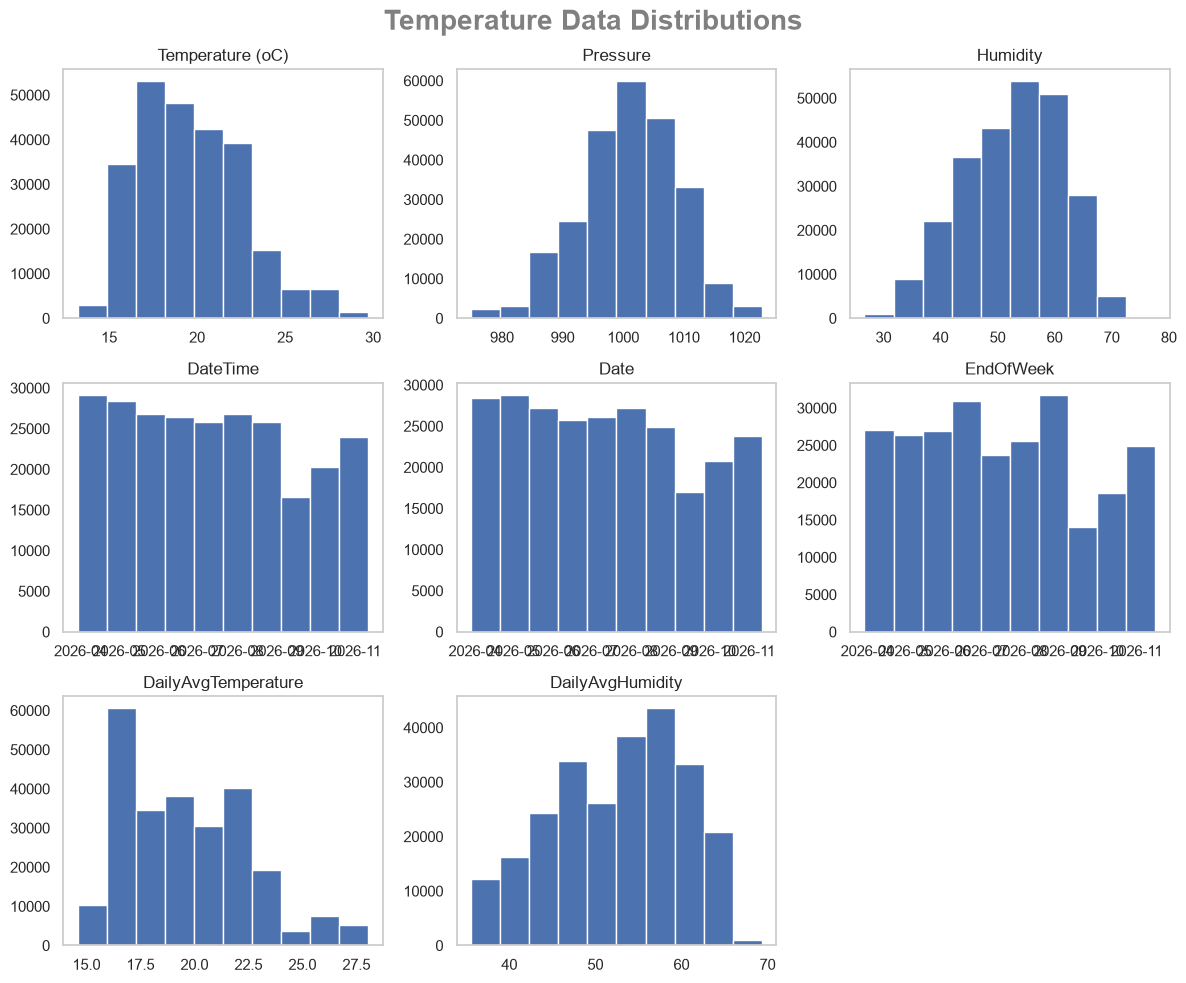

In [6]:
# show distributions
window_df.hist(
    grid=False, 
    figsize=(12, 10)
    );

plt.suptitle(
    "Temperature Data Distributions",
    fontsize=20,
    fontweight="bold",
    color="grey"
)

plt.tight_layout()

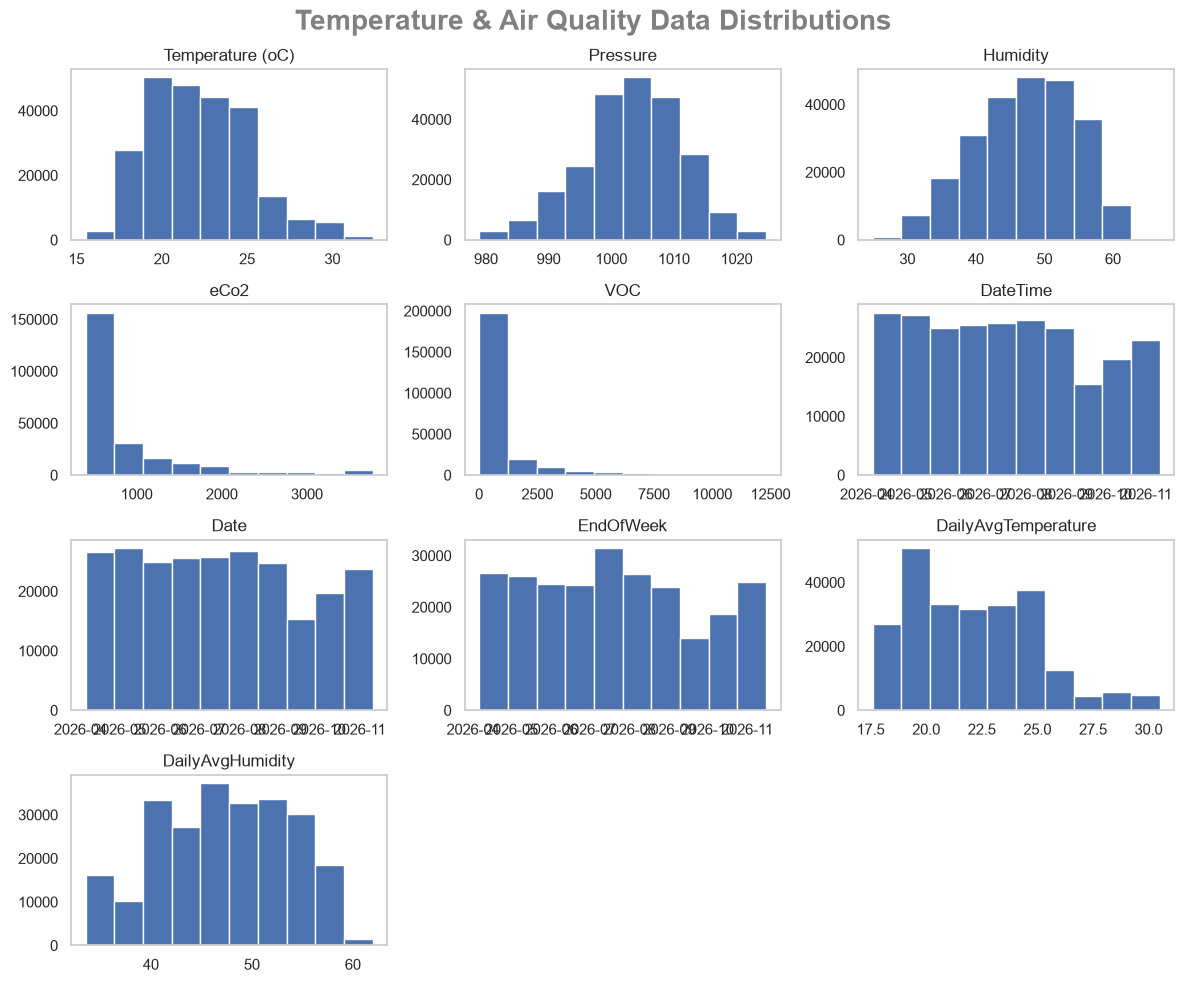

In [7]:
door_df.hist(
    grid=False, 
    figsize=(12, 10)
    );

plt.suptitle(
    "Temperature & Air Quality Data Distributions",
    fontsize=20,
    fontweight="bold",
    color="grey"
)
plt.tight_layout()

## EDA

1. Review how the data trends over time
2. Compute the difference between the two sensors - Does it get worse over times or specific periods?
3. When is humidity at its worse? (time during the day and month of the year)
4. Can we determine when humidity levels worsen? (ie the rate of change over time for when humidity levels increase)

#### Temperature Time Series

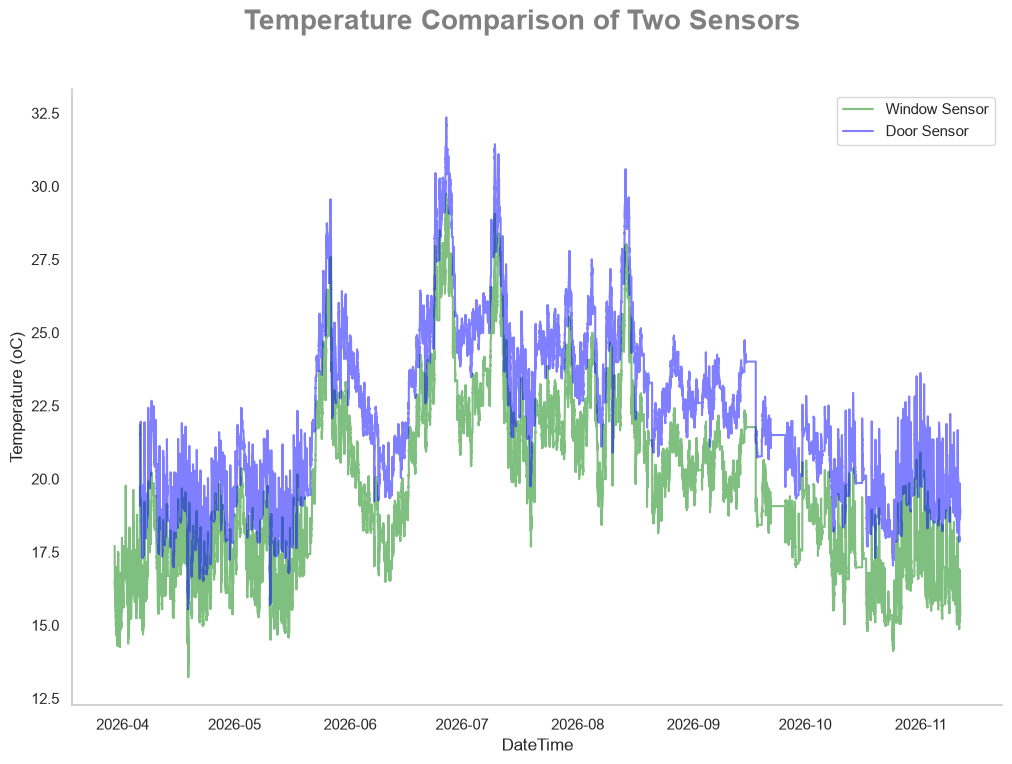

In [8]:
# review time series data trend over time

plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["Temperature (oC)"], 
    title="Temperature Comparison of Two Sensors",
    saved_name="Temperature Comparison of Two Sensors"
    )


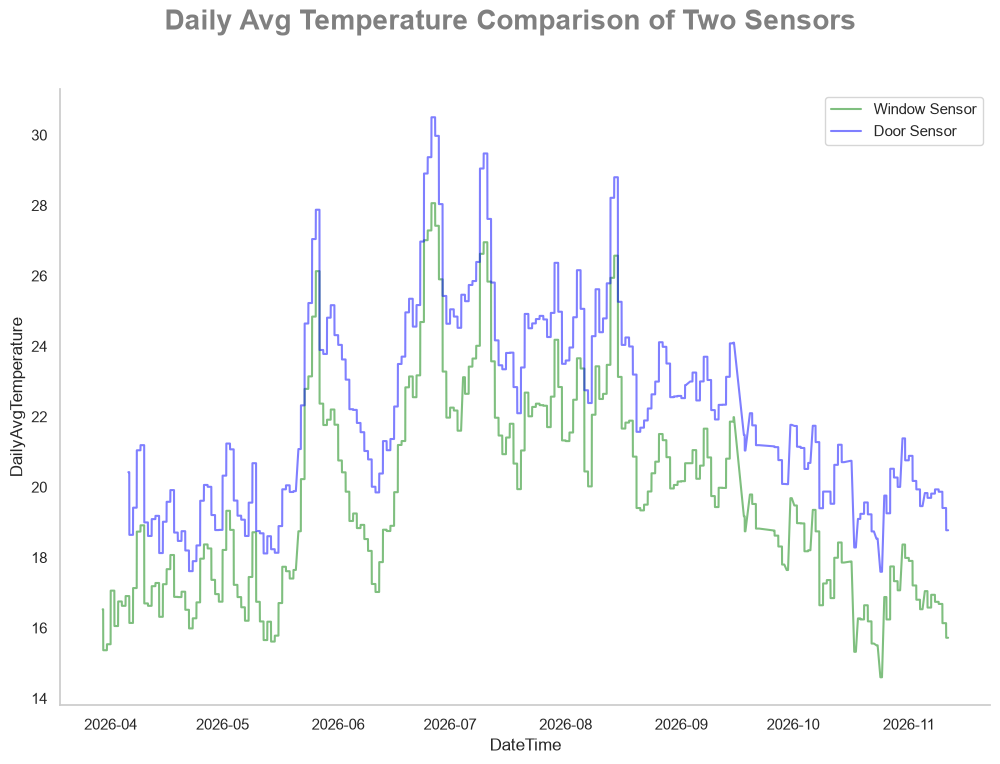

In [9]:
# show daily average time series plot
plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["DailyAvgTemperature"], 
    title="Daily Avg Temperature Comparison of Two Sensors",
    saved_name="Daily Avg Temperature Comparison of Two Sensors"
    )


##### **Notes**

1. There is evidence of cyclic behaviour -> The influence of time of the year and time of the day
2. The latest data shows that we are returing to temperatures of Apr 2026.


#### Humidity Time Series

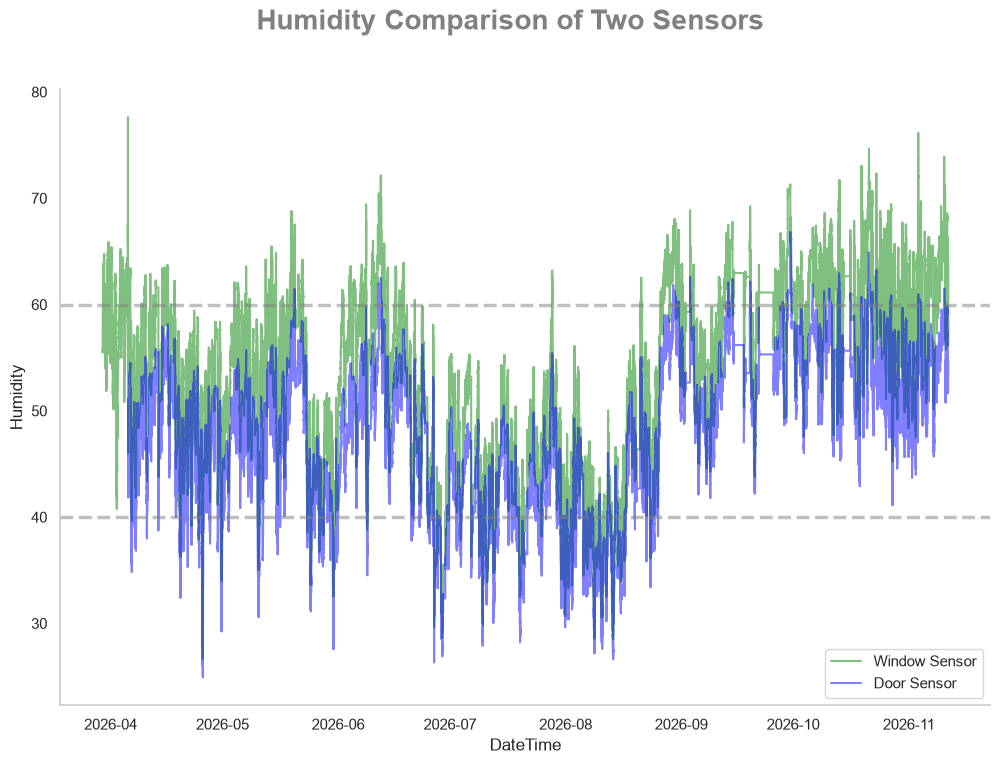

In [10]:
# now humidity
plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["Humidity"], 
    title="Humidity Comparison of Two Sensors",
    saved_name="Humidity Comparison of Two Sensors",
    add_hlines=True
    )

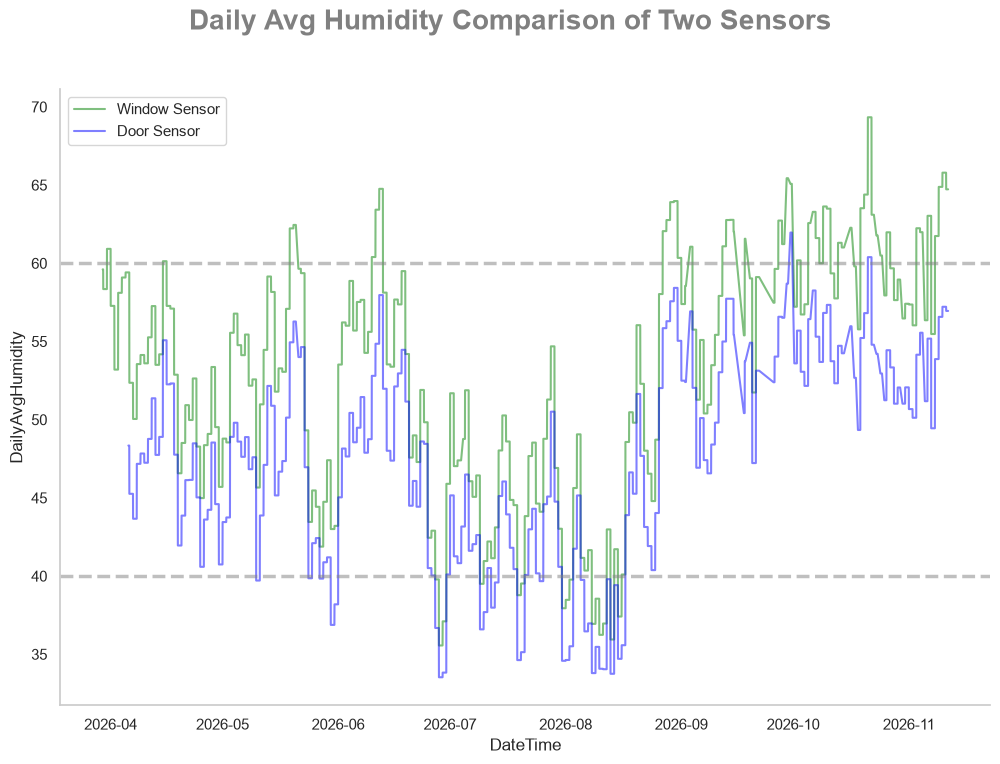

In [11]:
# Take the daily average and plot for ease of analysis
# show daily average time series plot
# according to Dreams, the range in which the humidity should be is in the range 40% and 60% for optimal comfort and health. 
# This plot will help visualize how the humidity levels from both sensors compare to this recommended range.
plot.plot_time_series(
    dfs=[window_df,door_df], 
    x_col="DateTime", 
    y_col=["DailyAvgHumidity"], 
    title="Daily Avg Humidity Comparison of Two Sensors",
    saved_name="Daily Avg Humidity Comparison of Two Sensors",
    add_hlines=True
    )




##### **Notes**

1. Summer months appear to be less humid than colder months.
2. Humidity levels typically lie above the max line (60%) for one of the sensors while the other appears to sit comformatably below the max line.

#### Temperature Sensor Drift

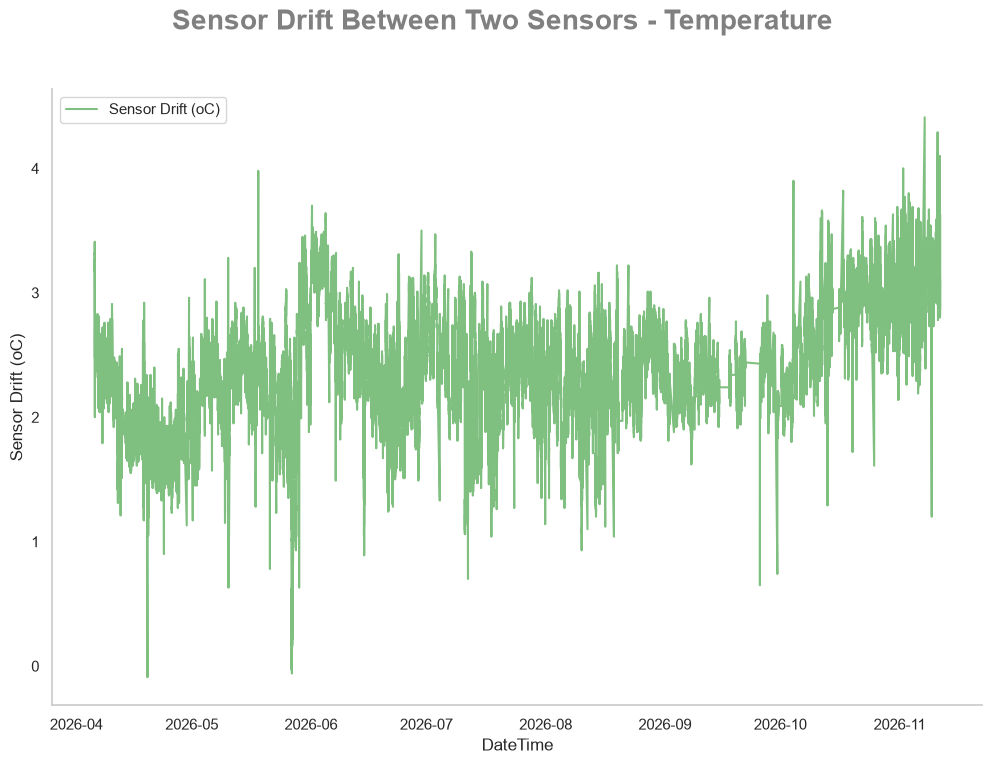

In [12]:
# How much of a difference is there between the two sensors?

tmp_sensor_drift = pd.DataFrame((door_df['Temperature (oC)'] - window_df['Temperature (oC)']).dropna())

tmp_sensor_drift.rename(columns={'Temperature (oC)': 'Sensor Drift (oC)'}, inplace=True)

plot.plot_time_series(
    dfs=[tmp_sensor_drift], 
    x_col="DateTime", 
    y_col=["Sensor Drift (oC)"], 
    title="Sensor Drift Between Two Sensors - Temperature",
    saved_name="Sensor Drift Between Two Sensors"
    )

count    239502.000000
mean          2.383798
std           0.450975
min          -0.090000
25%           2.100000
50%           2.390000
75%           2.670000
max           4.410000
Name: Sensor Drift (oC), dtype: float64 

Skewness: -0.1587924300124591
Kurtosis: 0.3752635587422848


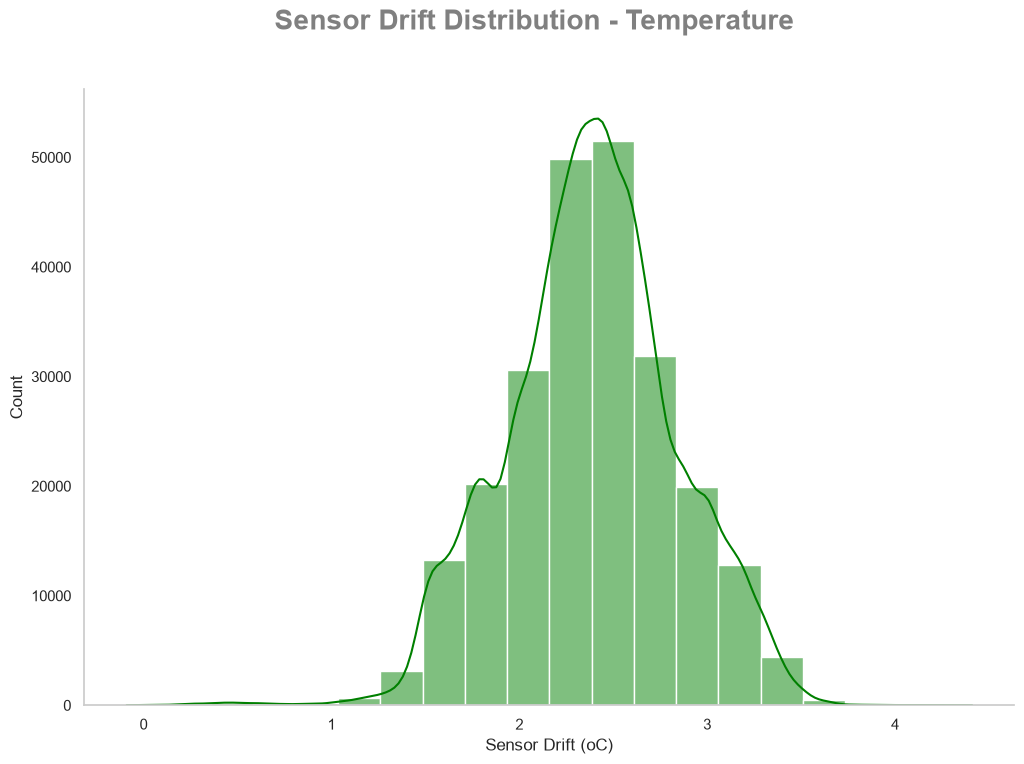

In [15]:
plot.plot_histogram(
    dfs=[tmp_sensor_drift],
    x_col='Sensor Drift (oC)',
    saved_name="Sensor Drift Between Two Sensors",
    title="Sensor Drift Distribution - Temperature",
    bins=20
)

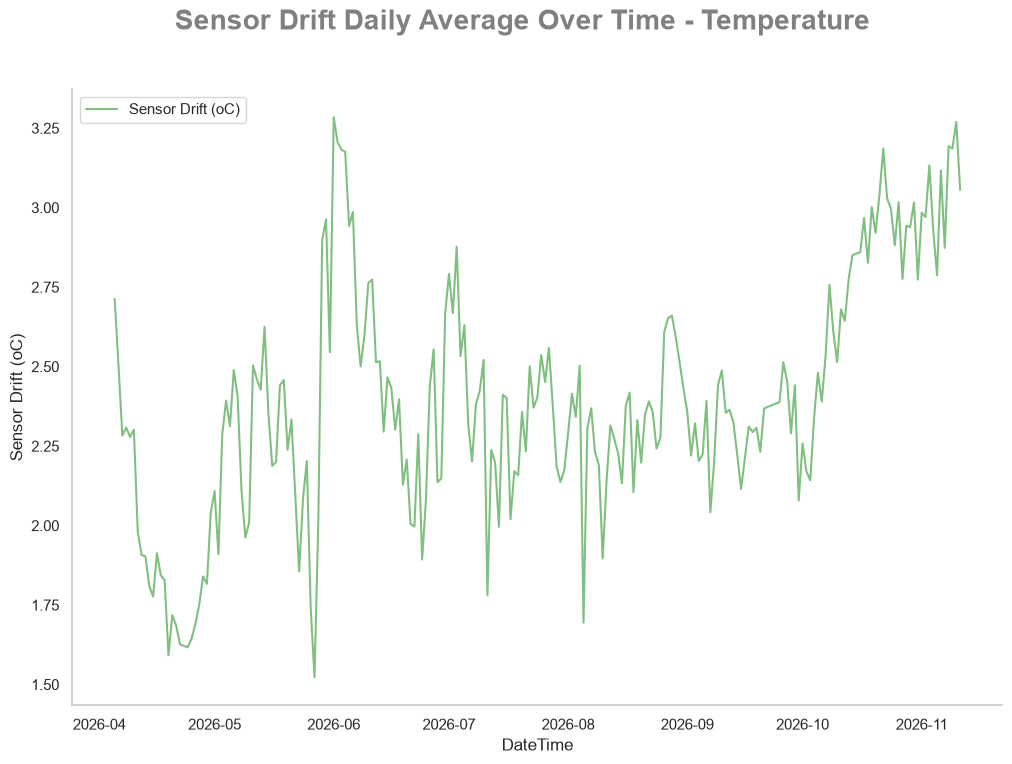

In [16]:
# How the sensor drift daily average changes over time
tmp_daily_avg_drift = tmp_sensor_drift.resample('1D').mean()


# plot the times series
plot.plot_time_series(
    dfs=[tmp_daily_avg_drift],
    x_col="DateTime",
    y_col=['Sensor Drift (oC)'],
    title="Sensor Drift Daily Average Over Time - Temperature",
    saved_name="Sensor Drift Daily Average Over Time - Temperature"
    )



##### Notes

The temperature drift between the two sesnors typically lie between 2 and 3 degrees celcius. This is interesting as the distance between the two sensors is approximately 9/10 meters, which suggests that their environments are quite different!

                            Sensor Drift (oC)  Daily Avg Door Temp (oC)  \
Sensor Drift (oC)                    1.000000                 -0.117074   
Daily Avg Door Temp (oC)            -0.117074                  1.000000   
Daily Avg Window Temp (oC)          -0.247557                  0.990992   

                            Daily Avg Window Temp (oC)  
Sensor Drift (oC)                            -0.247557  
Daily Avg Door Temp (oC)                      0.990992  
Daily Avg Window Temp (oC)                    1.000000  


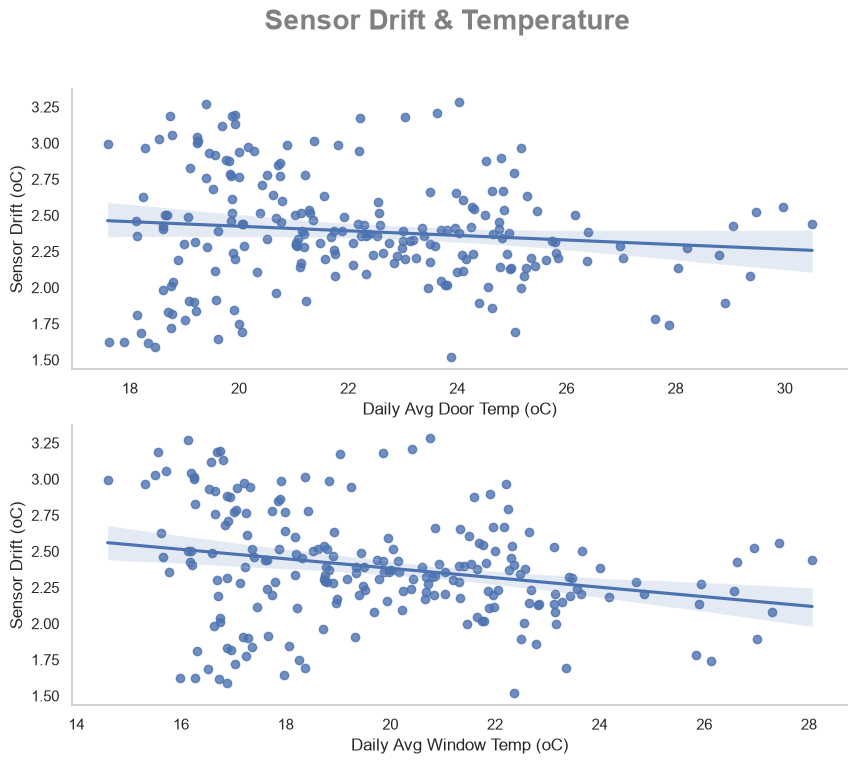

In [17]:
tmp_daily_avg_drift.rename(columns={'Temperature (oC)':'Sensor Drift (oC)'}, inplace=True)

# create daily avg features
tmp_daily_avg_drift['Daily Avg Door Temp (oC)'] = door_df['Temperature (oC)'].resample('D').mean()
tmp_daily_avg_drift['Daily Avg Window Temp (oC)'] = window_df['Temperature (oC)'].resample('D').mean()

plot.plot_relationships(
    df=tmp_daily_avg_drift,
    x_col=['Daily Avg Door Temp (oC)','Daily Avg Window Temp (oC)'],
    y_col='Sensor Drift (oC)',
    saved_name="Sensor Drift & Temperature",
    title="Sensor Drift & Temperature"
)

                            Sensor Drift (oC)  Daily Avg Door Temp (oC)  \
Sensor Drift (oC)                    1.000000                 -0.117074   
Daily Avg Door Temp (oC)            -0.117074                  1.000000   
Daily Avg Window Temp (oC)          -0.247557                  0.990992   
Daily Avg Door Humidity              0.354613                 -0.525510   
Daily Avg Window Humidity            0.457232                 -0.592653   

                            Daily Avg Window Temp (oC)  \
Sensor Drift (oC)                            -0.247557   
Daily Avg Door Temp (oC)                      0.990992   
Daily Avg Window Temp (oC)                    1.000000   
Daily Avg Door Humidity                      -0.559270   
Daily Avg Window Humidity                    -0.639250   

                            Daily Avg Door Humidity  Daily Avg Window Humidity  
Sensor Drift (oC)                          0.354613                   0.457232  
Daily Avg Door Temp (oC)              

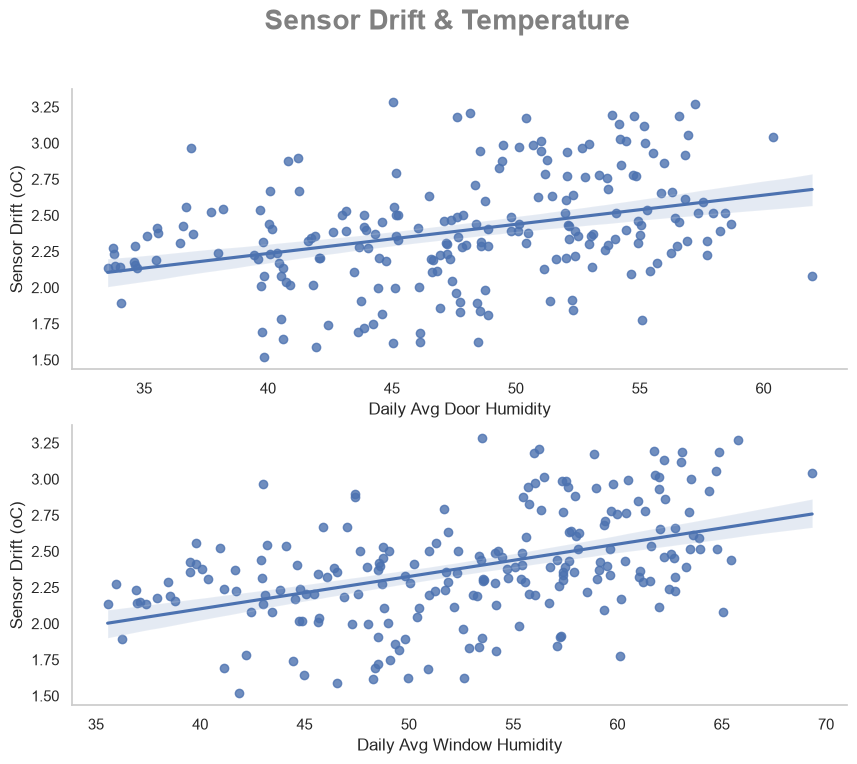

In [18]:
tmp_daily_avg_drift['Daily Avg Door Humidity'] = door_df['Humidity'].resample('D').mean()
tmp_daily_avg_drift['Daily Avg Window Humidity'] = window_df['Humidity'].resample('D').mean()

plot.plot_relationships(
    df=tmp_daily_avg_drift,
    x_col=['Daily Avg Door Humidity','Daily Avg Window Humidity'],
    y_col='Sensor Drift (oC)',
    saved_name="Sensor Drift & Temperature",
    title="Sensor Drift & Temperature"
)

##### **Notes**

1. The drift between 2 sensors appears to be getting worse as we draw closer to colder months - This suggests that one side of the room gets colder relative to the other side. However, more data is needed (Winter months) to determine if this is the case (a pattern should emergy where the difference remains around 2/3 degrees).
2. In addition to point one, the spikes in the daily avg sample appears to correlate with the spikes in temperature further evdidencing that one side of the room is more sensitive to temperature changes than the other. More evidence is required!
3. The counter argument to point one and two is the lack of evidence in correlation between drift and daily average temperature of each location.
4. There is a stronger relationship between Daily Avg Humidity levels and temperature drift, suggesting this factor may play a role. However, more analysis is required!
5. The positive relationship between Daily Avg Window Humidity and Sensor Drift suggests that the steady increase in humidity levels, the worse the drift get.

#### Humidity Sensor Drift

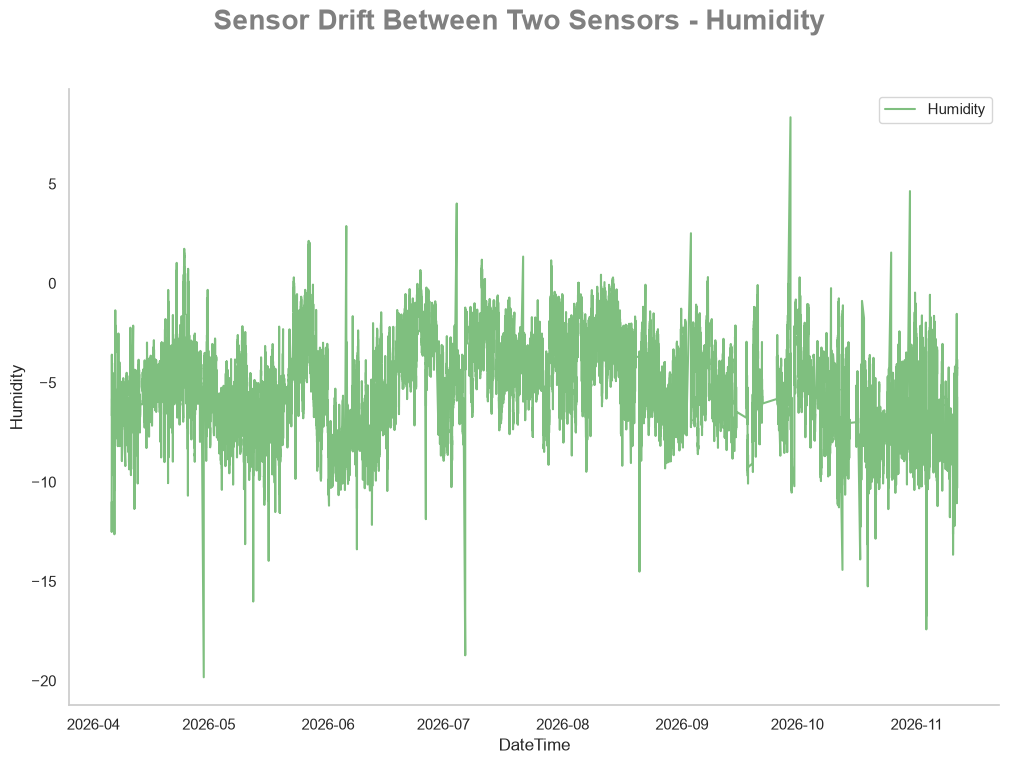

In [19]:
# How much of a difference is there between the two sensors humidity?

hum_sensor_drift = pd.DataFrame((door_df['Humidity'] - window_df['Humidity']).dropna())


plot.plot_time_series(
    dfs=[hum_sensor_drift], 
    x_col="DateTime", 
    y_col=["Humidity"], 
    title="Sensor Drift Between Two Sensors - Humidity",
    saved_name="Sensor Drift Between Two Sensors Over Time - Humidity"
    )

count    239502.000000
mean         -5.180067
std           2.082306
min         -19.828124
25%          -6.617188
50%          -5.126953
75%          -3.740234
max           8.352540
Name: Humidity, dtype: float64 

Skewness: -0.060447551859483084
Kurtosis: -0.09234372534613478


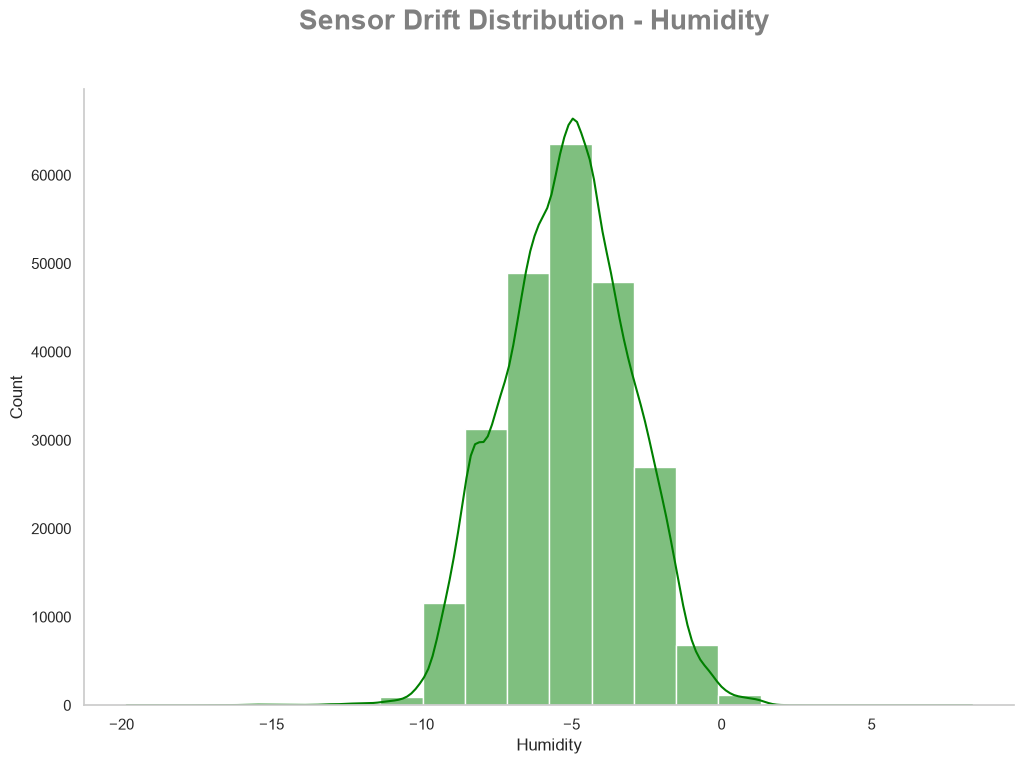

In [20]:
# show distribution
plot.plot_histogram(
    dfs=[hum_sensor_drift],
    x_col="Humidity",
    saved_name="Sensor Drift Distribution - Humidity",
    title="Sensor Drift Distribution - Humidity",
    bins=20
)

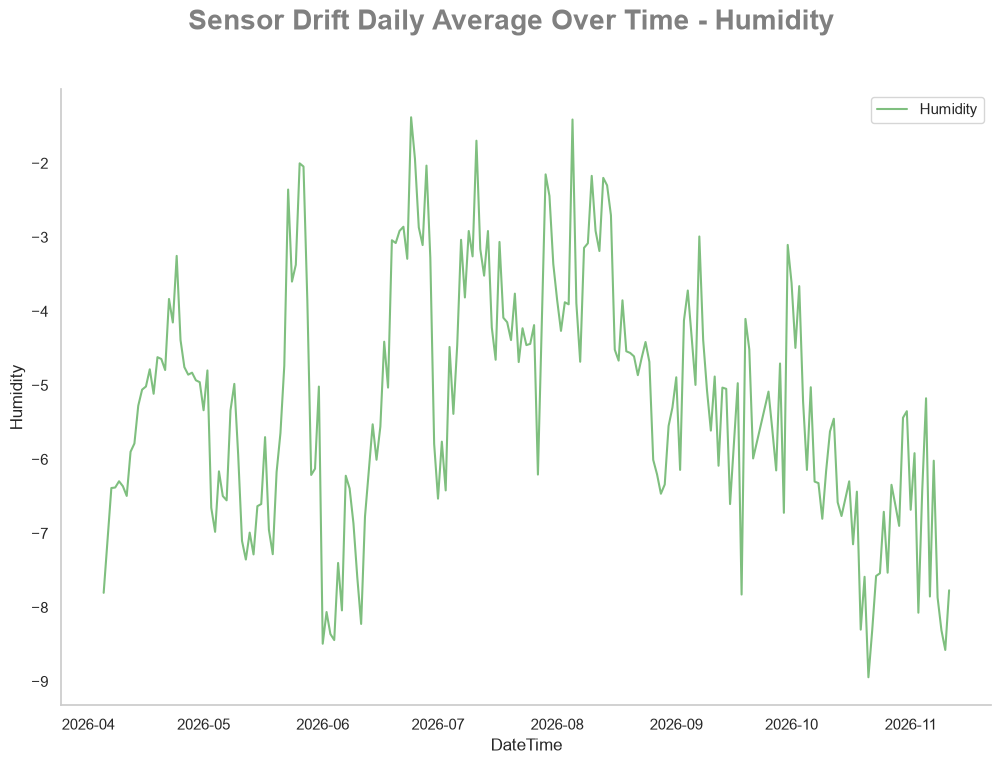

In [21]:
# review daily avg over time
hum_sensor_drift = hum_sensor_drift.resample('1D').mean()


# plot the times series
plot.plot_time_series(
    dfs=[hum_sensor_drift],
    x_col="DateTime",
    y_col=["Humidity"],
    title="Sensor Drift Daily Average Over Time - Humidity",
    saved_name="Sensor Drift Daily Average Over Time - Humidity"
    )

                            Humidity Sensor Drift  Daily Avg Door Temp (oC)  \
Humidity Sensor Drift                    1.000000                  0.652689   
Daily Avg Door Temp (oC)                 0.652689                  1.000000   
Daily Avg Window Temp (oC)               0.730769                  0.990992   

                            Daily Avg Window Temp (oC)  
Humidity Sensor Drift                         0.730769  
Daily Avg Door Temp (oC)                      0.990992  
Daily Avg Window Temp (oC)                    1.000000  


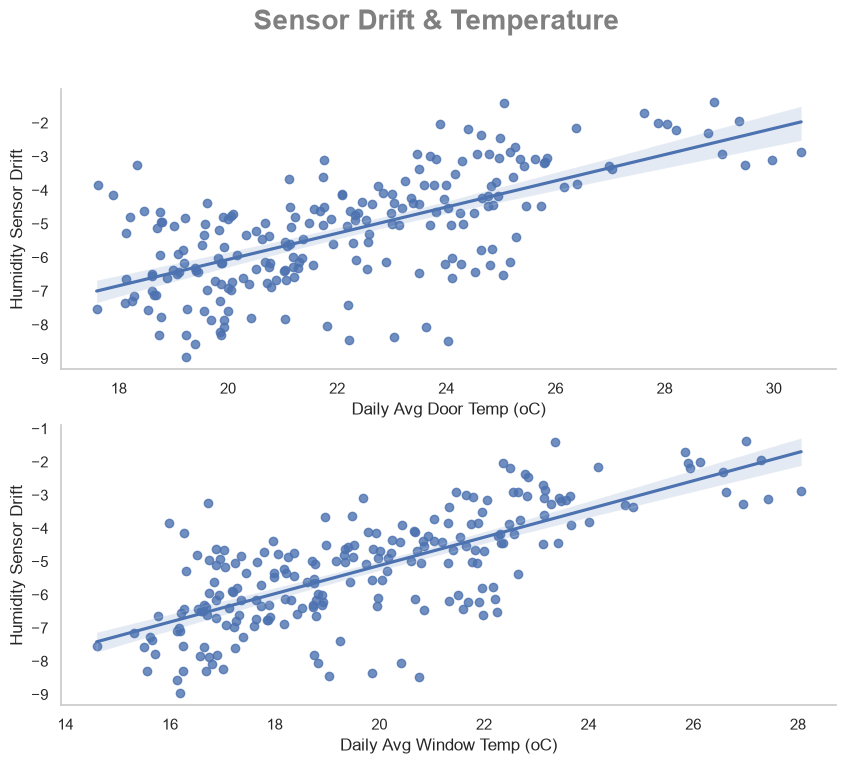

In [22]:
# what is the relationships between the two sensors temp and humidity drift?
hum_sensor_drift.rename(columns={'Humidity':'Humidity Sensor Drift'}, inplace=True)

# create daily avg features
hum_sensor_drift['Daily Avg Door Temp (oC)'] = door_df['Temperature (oC)'].resample('D').mean()
hum_sensor_drift['Daily Avg Window Temp (oC)'] = window_df['Temperature (oC)'].resample('D').mean()

plot.plot_relationships(
    df=hum_sensor_drift,
    x_col=['Daily Avg Door Temp (oC)','Daily Avg Window Temp (oC)'],
    y_col='Humidity Sensor Drift',
    saved_name="Sensor Drift & Temperature",
    title="Sensor Drift & Temperature"
)

##### Notes

1. The relationships plotted suggests that in the colder months, the drift between sensors for humidity gets worse meaning humidity levels become wrose on one side of the room compared to the other.
2. The wondow is more sensitive to drift in colder temperatures, meaning humidity is ~5% to 9% worse that the door sensor.
3. The change in humidity drift is more sensitive compared to temperature.

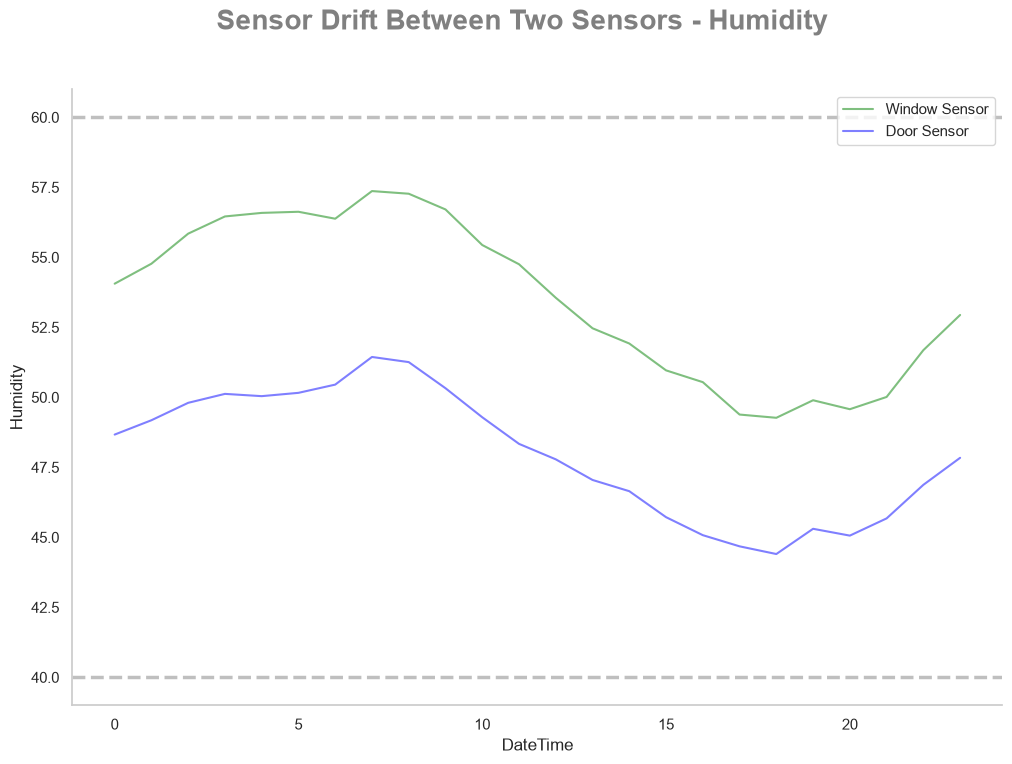

In [23]:
# lets do the same except this time focus on time of the day

hum_hourly_win = window_df.groupby(window_df.index.hour)['Humidity'].median().reset_index()
hum_hourly_door = door_df.groupby(door_df.index.hour)['Humidity'].median().reset_index()

# plot the line
plot.plot_time_series(
    dfs=[hum_hourly_win,hum_hourly_door], 
    x_col='DateTime', 
    y_col=["Humidity"], 
    title="Sensor Drift Between Two Sensors - Humidity",
    saved_name="Sensor Drift Between Two Sensors Over Time - Humidity",
    add_hlines=True
    )

#### Notes

1. Humidity levels typically peak around 7am/8am.
2. The lowest levels typicall lie between 4pm and 6pm then augements as it goes into the night.
3. The negative of taking the entire sample is that it consider warmer months where humidity levels were lower. Next step is to filter the data from Oct to date and compare the differences!

To tackle the humidity problem, it seems that the worse levels happens during the night/early morning. It would be interesting to see the data as we get into the winter!

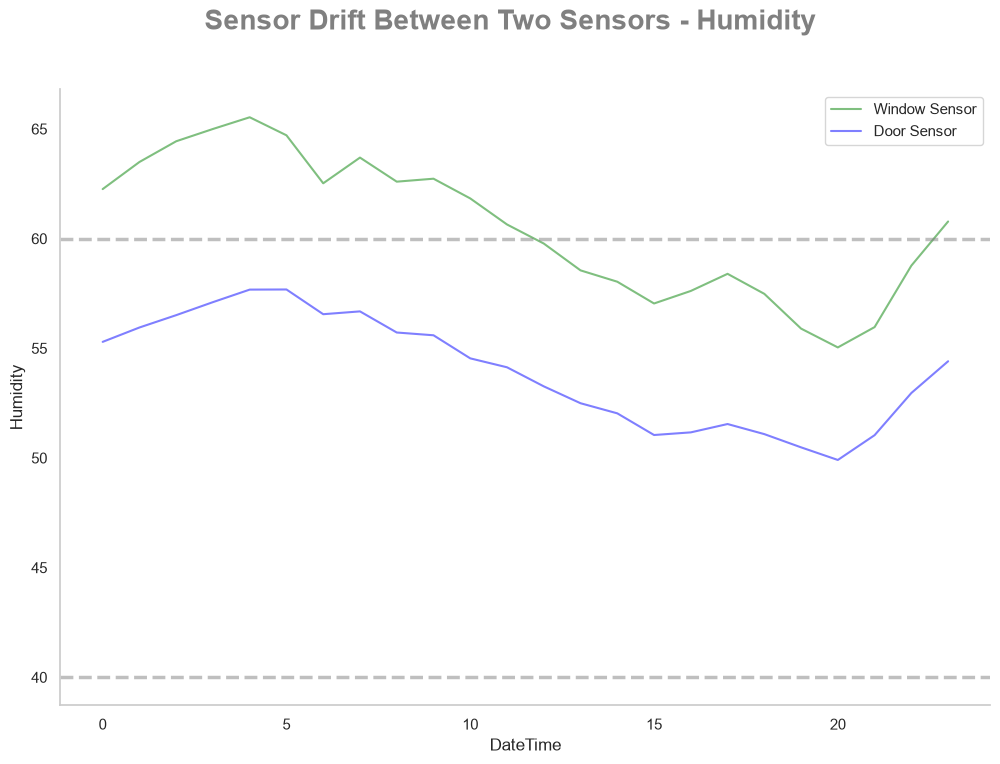

In [24]:
# lets do the same except this time focus on time of the day
win_oct_to_date_mask = (window_df.index >= '2026-10-01') 
door_oct_to_date_mask = (door_df.index >= '2026-10-01') 

cold_hum_hourly_win = (
    window_df
    .loc[win_oct_to_date_mask]
    .groupby(window_df.loc[win_oct_to_date_mask].index.hour)['Humidity']
    .median()
    .reset_index()
    )

cold_hum_hourly_door = (
    door_df
    .loc[door_oct_to_date_mask]
    .groupby(door_df.loc[door_oct_to_date_mask].index.hour)['Humidity']
    .median()
    .reset_index()
    )

# plot the line
plot.plot_time_series(
    dfs=[cold_hum_hourly_win,cold_hum_hourly_door], 
    x_col='DateTime', 
    y_col=["Humidity"], 
    title="Sensor Drift Between Two Sensors - Humidity",
    saved_name="Sensor Drift Between Two Sensors From Oct 2026 to Date - Humidity",
    add_hlines=True
    )


##### Notes

This is a classic case of data drift where newer data distribution has shifted from older data -> the influence of changing seasons! however, the overall pattern remains the same where we observe an S-curve over time, but peaks earlier than the overall dataset (around 4am rather than 5/6am).

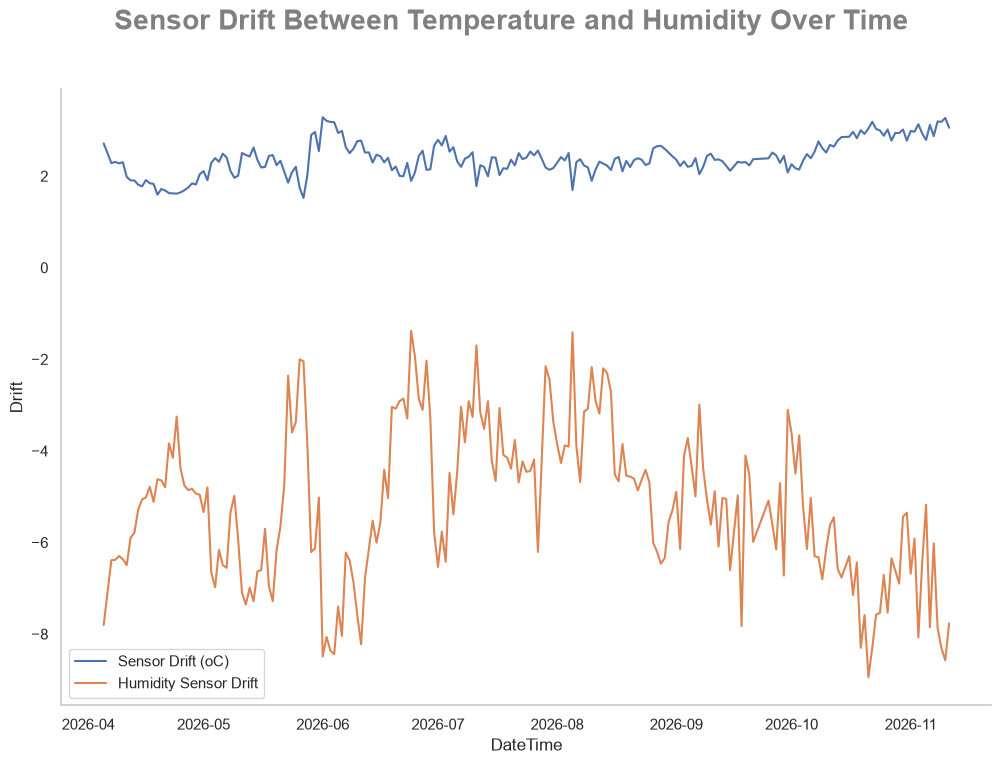

In [25]:
fig = plt.figure(figsize=(12,8))

hum_and_tmp_drift = pd.concat(
    [
        tmp_daily_avg_drift[['Sensor Drift (oC)']], 
        hum_sensor_drift[['Humidity Sensor Drift']]
        ], 
        axis=1
)

for feature in ['Sensor Drift (oC)','Humidity Sensor Drift']:
    sns.lineplot(
        data=hum_and_tmp_drift,
        x=hum_and_tmp_drift.index,
        y=feature,
        label=feature
    )

plt.legend()

# clean up for standrad settings
plot.plot_cleanup(
    title="Sensor Drift Between Temperature and Humidity Over Time",
    xlabel="DateTime",
    ylabel="Drift"
)

# save the image
plot.save_image(
    file_name="Sensor Drift Between Temperature and Humidity Over Time",
    fig=fig
)

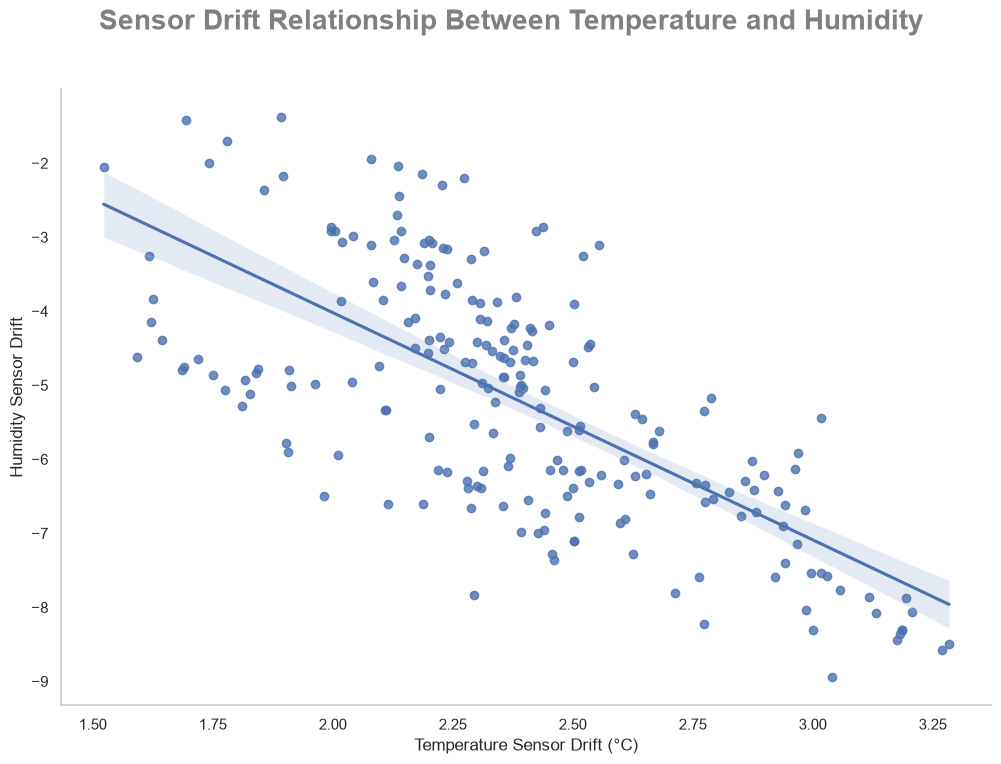

In [26]:
fig = plt.figure(figsize=(12,8))


sns.regplot(
    data=hum_and_tmp_drift.dropna(),
    x='Sensor Drift (oC)',
    y='Humidity Sensor Drift',
    label='Humidity Sensor Drift'
)

plot.plot_cleanup(
    title="Sensor Drift Relationship Between Temperature and Humidity",
    xlabel="Temperature Sensor Drift (°C)",
    ylabel="Humidity Sensor Drift"
)

# save the image
plot.save_image(
    file_name="Sensor Drift Relationship Between Temperature and Humidity",
    fig=fig
)